En base al archivo componente_1.ipy, respóndeme las siguientes preguntas: 

¿Cuál es la linea base y cuál es su incertidumbre (es decir, cuánto dinero se está gastando ahora por entrega y cuánto se podría ahorrar)?
Se usa bootstrap por conglomerados para estimar nuevos intervalos de confianza para diferentes grupos como: tipo de vehículo, distancia a recorrer, tiempo para hacer una entrega (menciona si había independencia entre diferentes grupos o e si había independencia entre viajes pertenecientes a un mismo grupo)?
¿Qué periodo cubre la línea base, por qué ese, y en qué cortes (ruta, producto, proveedor, mes) se reporta?

¿La utilización que se decidió para este reto se basa en el peso? 
¿Para qué sirve cada una de las fórmulas de la foto (utilización del peso real)? ¿Sirven para saber cuál habría sido la mayor utilización de la dimensión que amarra (o qué peso se utilizó)?
¿Para este archivo se reporta la distribución de u por tipo de camión y con qué frecuencia amarra cada dimensión?
¿El costo total se reporta por viaje, tonelada, y por tonelada-kilómetro? ¿El orden de eficencia de los tipos de camiones cambia según la métrica: costo total por viaje, por tonelada, y por tonelada-kilómetro (en base a lo mencionado previamente, dado que el orden podría cambiar dependiendo de qué métrica estés mirando)?

Si es posible, verifica el contenido de este link (específicamente la sección 6) y dime si los datos relativos al peso total mencionados en el glosario dentro de la carpeta data/plata/Glosario_tabla_oro.md respetan los límites estipulados en el siguiente link: https://platiica.economia.gob.mx/wp-content/uploads/sites/2/PDF_Normas_Publicas/012-SCT-2-2017.pdf

¿Hay casos en los que, para una misma carga, se identificó un tipo de camión de menor costo que podría haber llevado esa carga en vez del tipo de camión que en realidad la transportó?

Utilización real (volumen, peso, etc.) = de la capacidad máxima del camión, qué tanto se utilizó.

Nota: Para la cota superior, no sabemos si ese camión estaba disponible en ese mismo momento porque habría que usar datos hipotéticos para crear escenarios que nos ayuden a respaldar nuestras suposiciones/hipótesis. 

Queda estudiar el componente 2...

In [4]:
# Propósito: Importar librerías y definir la ruta de la capa oro.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from pathlib import Path

DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS/'data'/'plata'
DATA_ADRESS = DATA_DIR/'viajes_foraneos_oro.csv'

In [5]:
# Propósito: Cargar la capa oro y revisar cómo aparecen los camiones Portacintas / Big Coil.
df = pd.read_csv(DATA_ADRESS, sep=',')
portacintas = df[df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|COIL', case=False, na=False)]
print("Valores únicos en FAMILIA_CAMION_DESC para portacintas:")
print(portacintas['FAMILIA_CAMION_DESC'].value_counts())
print("\nValores únicos en Tipo Camión para portacintas:")
print(portacintas['Tipo Camión'].value_counts())

Valores únicos en FAMILIA_CAMION_DESC para portacintas:
FAMILIA_CAMION_DESC
PLATAFORMA 3 EJES NEUMATICA BIG COIL             3692
PLATAFORMA 3 EJES NEUMATICA BASES PORTACINTAS    1968
Name: count, dtype: int64

Valores únicos en Tipo Camión para portacintas:
Tipo Camión
Plataforma 3 ejes Neumática BIG COIL             3692
Plataforma 3 ejes Neumática Bases Portacintas    1968
Name: count, dtype: int64


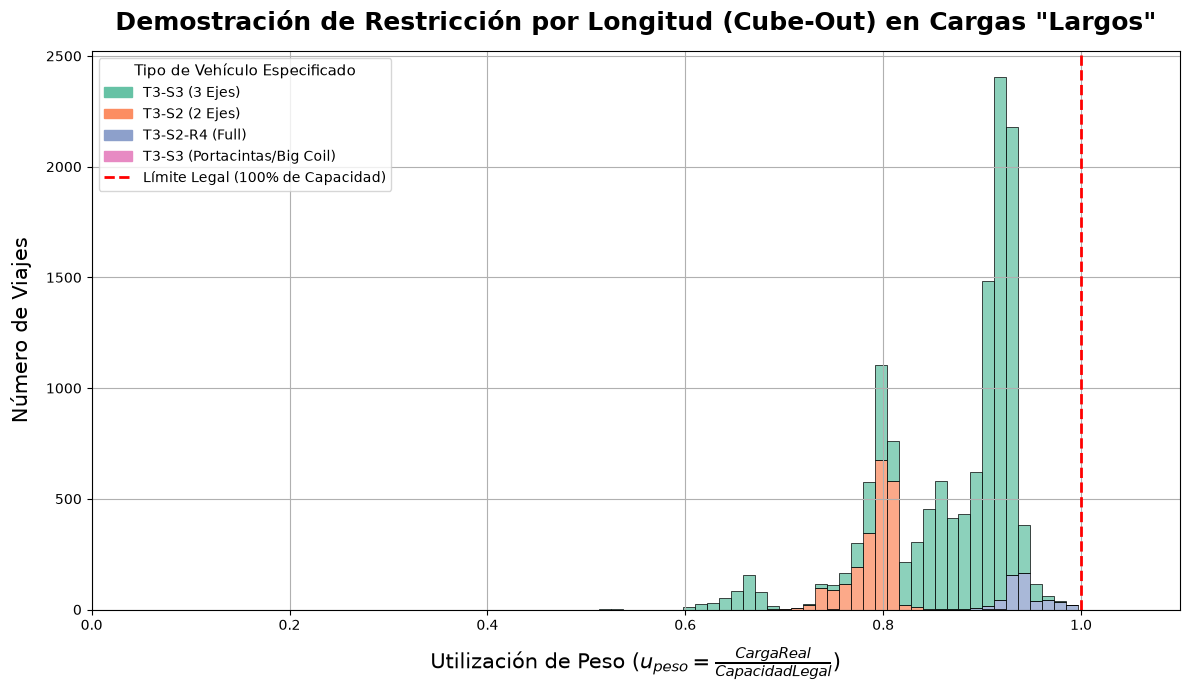

In [6]:
# Propósito: Reclasificar camiones por peso, separar Portacintas y graficar u_peso de las cargas 'Largos' (restricción por largo).
if 'GRUPO_PLANTA_ORIGEN' not in df.columns:
    np.random.seed(42)
    df['GRUPO_PLANTA_ORIGEN'] = np.random.choice(['Largos', 'Revestidos', 'Bodega', 'CeSer'], size=len(df), p=[0.3, 0.4, 0.2, 0.1])

# DIFERENCIAR PORTACINTAS / BIG COIL
# Primero asignamos la nomenclatura base que ya teníamos
df['Programado_kg'] = df['Programado (Peso)'] * 1000
LIMITE_2_EJES = 32000; LIMITE_3_EJES = 38500; LIMITE_FULL = 46000 #Límites de peso basados en las normas oficiales de México.

condiciones_base = [
    (df['Programado_kg'] > LIMITE_3_EJES),
    (df['Programado_kg'] > LIMITE_2_EJES) & (df['Programado_kg'] <= LIMITE_3_EJES),
    (df['Programado_kg'] <= LIMITE_2_EJES) & (df['FAMILIA_CAMION_DESC'].astype(str).str.contains('3 EJES', case=False, na=False)),
    (df['Programado_kg'] <= LIMITE_2_EJES) & (df['FAMILIA_CAMION_DESC'].astype(str).str.contains('2 EJES', case=False, na=False))
]
nomenclaturas_base = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (3 Ejes)', 'T3-S2 (2 Ejes)']
df['Nomenclatura_Base'] = np.select(condiciones_base, nomenclaturas_base, default='T3-S2 (2 Ejes)')

capacidades = [LIMITE_FULL, LIMITE_3_EJES, LIMITE_3_EJES, LIMITE_2_EJES]
df['Capacidad_Max_kg'] = np.select(condiciones_base, capacidades, default=LIMITE_2_EJES)

# Separar los Portacintas de los 3 Ejes genéricos
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Nomenclatura_Final'] = np.where(mascara_portacintas, 'T3-S3 (Portacintas/Big Coil)', df['Nomenclatura_Base'])

# CALCULAR UTILIZACIÓN DE PESO
df['u_peso'] = df['Porcentaje_Utilizacion_Real']/100

# FILTRAR Y GRAFICAR "LARGOS"
df_largos = df[df['GRUPO_PLANTA_ORIGEN'] == 'Largos'].copy()

orden_camiones = df_largos['Nomenclatura_Final'].unique()
paleta_colores = sns.color_palette('Set2', n_colors=len(orden_camiones))

# Generar el gráfico forzando el orden de los colores (hue_order)
plt.figure(figsize=(12, 7))
ax = sns.histplot(
    data=df_largos, 
    x='u_peso', 
    hue='Nomenclatura_Final',
    hue_order=orden_camiones, # Forzamos el orden
    multiple="stack", 
    bins=40, 
    palette=paleta_colores,
    edgecolor='black',
    linewidth=0.5
)

# Dibujar la línea de restricción dura
linea_limite = plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Límite Legal (100% de Capacidad)')

manejadores_leyenda = []

for i, nombre_camion in enumerate(orden_camiones):
    parche = mpatches.Patch(color=paleta_colores[i], label=nombre_camion)
    manejadores_leyenda.append(parche)

manejadores_leyenda.append(linea_limite)

plt.legend(
    handles=manejadores_leyenda, 
    title='Tipo de Vehículo Especificado', 
    loc='upper left',
    fontsize='10', 
    title_fontsize='11',
    frameon=True
)

plt.title('Demostración de Restricción por Longitud (Cube-Out) en Cargas "Largos"', fontsize=18, fontweight='bold', pad=15)
plt.xlabel('Utilización de Peso ($u_{peso} = \\frac{Carga Real}{Capacidad Legal}$)', fontsize=15, labelpad=10)
plt.ylabel('Número de Viajes', fontsize=15, labelpad=10)
plt.xlim(0, 1.1)

plt.tight_layout()
plt.grid()
plt.show()

In [7]:
# Propósito: Utilización efectiva u_i = max(u_peso, u_volumen) y dimensión que amarra por tipo de camión (u_volumen es un supuesto, no medido).
df['u_peso'] = df['Porcentaje_Utilizacion_Real'] / 100

# Filtrar exclusivamente las cargas donde la dimensión que amarra asume ser el volumen/largo
df_largos = df[df['GRUPO_PLANTA_ORIGEN'] == 'Largos'].copy()

df['u_volumen'] = np.where(df['GRUPO_PLANTA_ORIGEN'] == 'Largos', 1.0, df['u_peso'] * 0.85)

# Utilización Efectiva (u_i = max(q_ik / c_ik))
df['u_efectiva'] = df[['u_peso', 'u_volumen']].max(axis=1)

# Identificar la Dimensión que Amarra (k*_i = argmax(q_ik / c_ik))
df['Dimension_Amarra'] = np.where(df['u_volumen'] >= df['u_peso'], 'Volumen/Largo', 'Peso Legal')

# Mostrar las frecuencias de amarre
print("Frecuencia de la dimensión que amarra por tipo de camión:")
display(pd.crosstab(df['Nomenclatura_Inferida'], df['Dimension_Amarra'], margins=True))

Frecuencia de la dimensión que amarra por tipo de camión:


Dimension_Amarra,Peso Legal,Volumen/Largo,All
Nomenclatura_Inferida,,,
Cama Baja Doble Piso,167,0,167
Heavy,34,0,34
Plataforma larga 48 pies,343,0,343
Plataforma larga 53 pies,2,0,2
T3-S2 (2 Ejes),6673,2150,8823
T3-S2-R4 (Full),287,528,815
T3-S3 (3 Ejes),26981,10640,37621
T3-S3 (Portacintas/Big Coil),5654,5,5659
Torton,1674,0,1674


Estadísticas de utilización (u_peso) para cargas amarradas por Báscula:


,count,mean,median,min,max,std
Nomenclatura_Inferida,,,,,,
Cama Baja Doble Piso,167,0.830,0.835,0.567,0.975,0.076
Plataforma larga 48 pies,343,0.920,0.920,0.473,1.191,0.082
Plataforma larga 53 pies,2,1.024,1.024,1.007,1.041,0.024
T3-S2 (2 Ejes),6673,0.752,0.765,0.091,0.996,0.078
T3-S2-R4 (Full),287,0.754,0.753,0.747,0.775,0.005
T3-S3 (3 Ejes),26981,0.806,0.831,0.278,0.999,0.124
T3-S3 (Portacintas/Big Coil),5654,0.730,0.701,0.208,0.997,0.091
Torton,1674,0.744,0.769,0.329,0.873,0.087
Tortoneta,250,0.766,0.771,0.585,0.896,0.066


C:\Users\sborb\AppData\Local\Temp\ipykernel_37416\1866363601.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


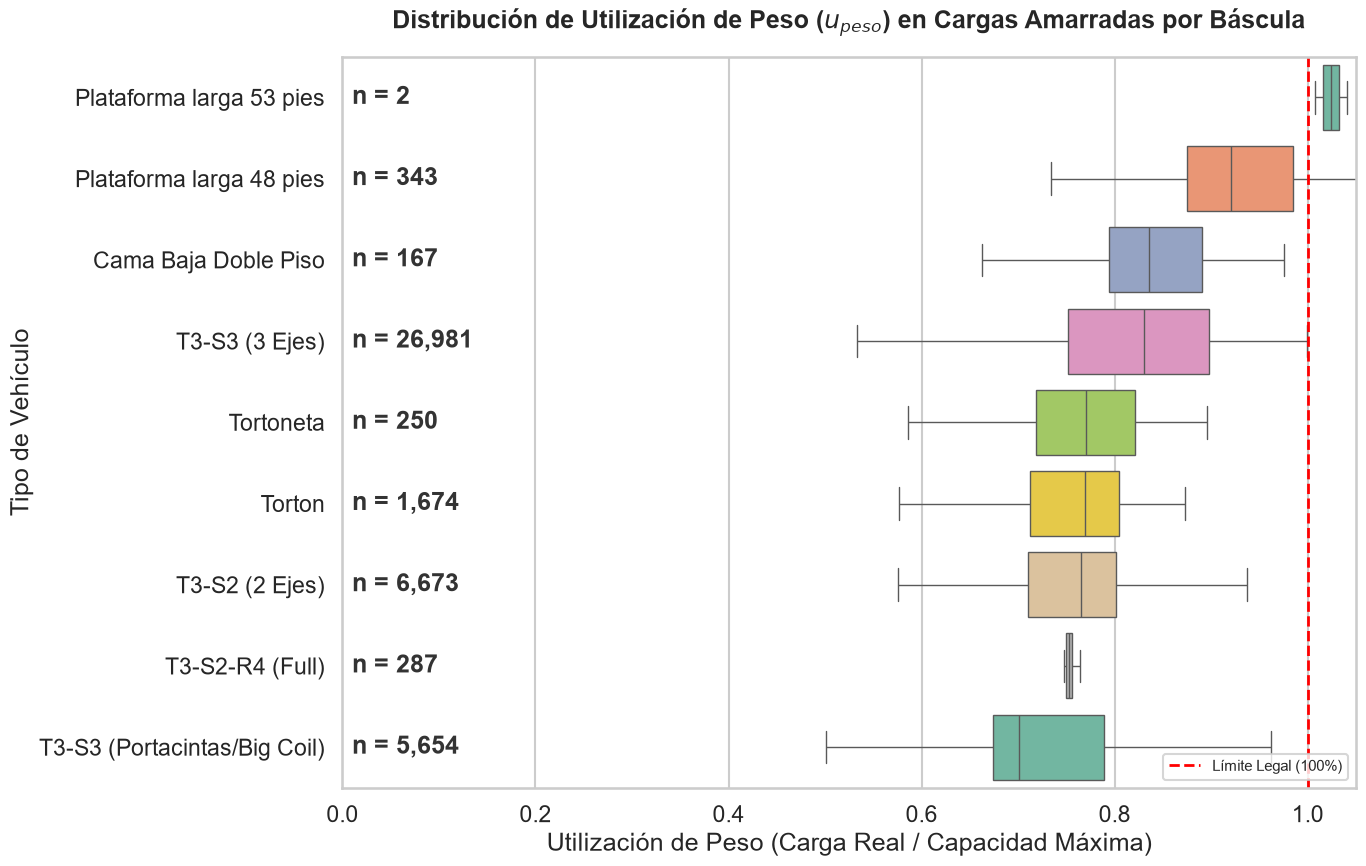

In [8]:
# Propósito: Distribución de u_peso por tipo de camión en viajes que amarran por peso (tabla y boxplot).
df['Dimension_Amarra'] = np.where(df['GRUPO_PLANTA_ORIGEN'] == 'Largos', 'Volumen/Largo', 'Peso Legal')
df_peso = df[(df['Dimension_Amarra'] == 'Peso Legal') & (df['Nomenclatura_Inferida'] != 'Heavy')].copy()

# Calcular y mostrar las estadísticas descriptivas
stats = df_peso.groupby('Nomenclatura_Inferida')['u_peso'].agg(
    count='count', mean='mean', median='median', min='min', max='max', std='std'
).round(3)

print("Estadísticas de utilización (u_peso) para cargas amarradas por Báscula:")
display(stats)

# Generar el Boxplot
plt.figure(figsize=(14, 9))
sns.set_theme(style="whitegrid", context="talk")

# Ordenar las cajas de mayor a menor mediana
orden_cajas = df_peso.groupby('Nomenclatura_Inferida')['u_peso'].median().sort_values(ascending=False).index

ax = sns.boxplot(
    data=df_peso, 
    y='Nomenclatura_Inferida', 
    x='u_peso', 
    order=orden_cajas,
    palette='Set2',
    showfliers=False # Oculta los diamantes de outliers para limpiar la vista
)

# Añadir las cantidades (n) de la tabla directamente al inicio de cada caja
for i, camion in enumerate(orden_cajas):
    cantidad = stats.loc[camion, 'count']
    ax.text(0.01, i, f'n = {int(cantidad):,}', verticalalignment='center', size=18, weight='bold', color='#333333')

# Formato y etiquetas
plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Límite Legal (100%)')
plt.title('Distribución de Utilización de Peso ($u_{peso}$) en Cargas Amarradas por Báscula', pad=20, fontweight='bold')
plt.xlabel('Utilización de Peso (Carga Real / Capacidad Máxima)')
plt.ylabel('Tipo de Vehículo')
plt.legend(loc='lower right', frameon=True, fontsize = 11)
plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()

Nulos en Kilometros_Ruta: 17666

Estadísticas de Kilometros_Ruta:
count    37722.000000
mean       651.783803
std        470.494751
min          1.451900
25%        240.277100
50%        499.452100
75%        943.424000
max       4054.364000
Name: Kilometros_Ruta, dtype: float64

Tercil 33%: 362.4 km
Tercil 66%: 796.7 km

Gráfica guardada como distribucion_distancias.png


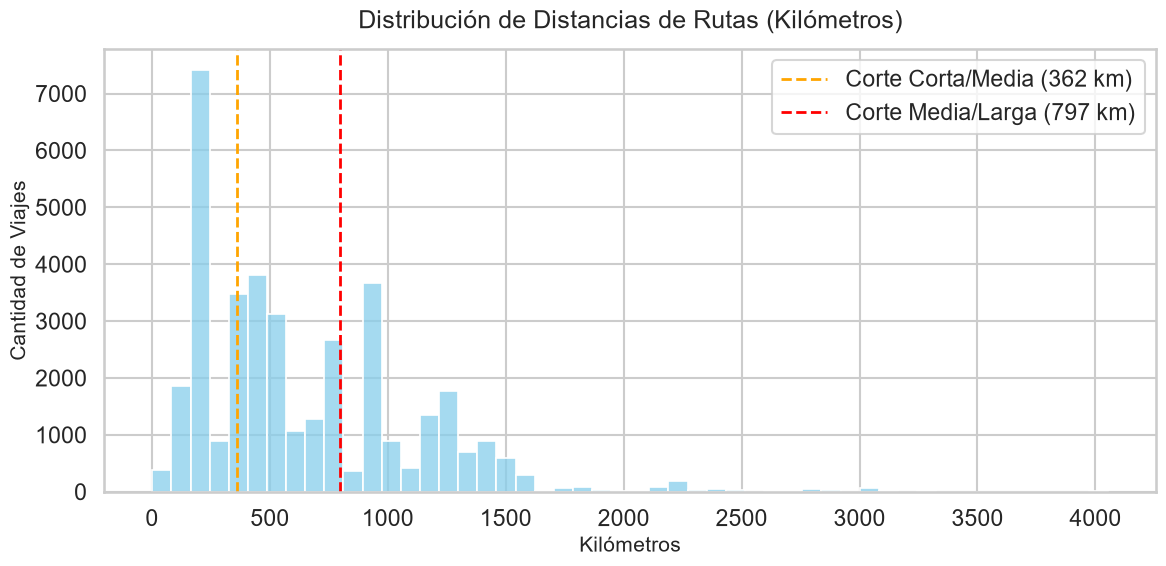

In [9]:
# Propósito: Distribución de distancias y cortes por terciles (corta / media / larga).
nulos = df['Kilometros_Ruta'].isna().sum()
print(f"Nulos en Kilometros_Ruta: {nulos}")

# Estadísticas descriptivas de la distancia
stats_km = df['Kilometros_Ruta'].describe()
print("\nEstadísticas de Kilometros_Ruta:")
print(stats_km)

# Calcular percentiles para proponer cortes (terciles)
tercil_33 = df['Kilometros_Ruta'].quantile(0.33)
tercil_66 = df['Kilometros_Ruta'].quantile(0.66)
print(f"\nTercil 33%: {tercil_33:.1f} km")
print(f"Tercil 66%: {tercil_66:.1f} km")

# Graficar la distribución
plt.figure(figsize=(12, 6))
sns.histplot(df['Kilometros_Ruta'], bins=50, color='skyblue')
plt.axvline(tercil_33, color='orange', linestyle='--', linewidth=2, label=f'Corte Corta/Media ({tercil_33:.0f} km)')
plt.axvline(tercil_66, color='red', linestyle='--', linewidth=2, label=f'Corte Media/Larga ({tercil_66:.0f} km)')

plt.title('Distribución de Distancias de Rutas (Kilómetros)', fontsize=18, pad=15)
plt.xlabel('Kilómetros', fontsize=15)
plt.ylabel('Cantidad de Viajes', fontsize=15)
plt.legend()
plt.tight_layout()
#plt.savefig('distribucion_distancias.png')
print("\nGráfica guardada como distribucion_distancias.png")

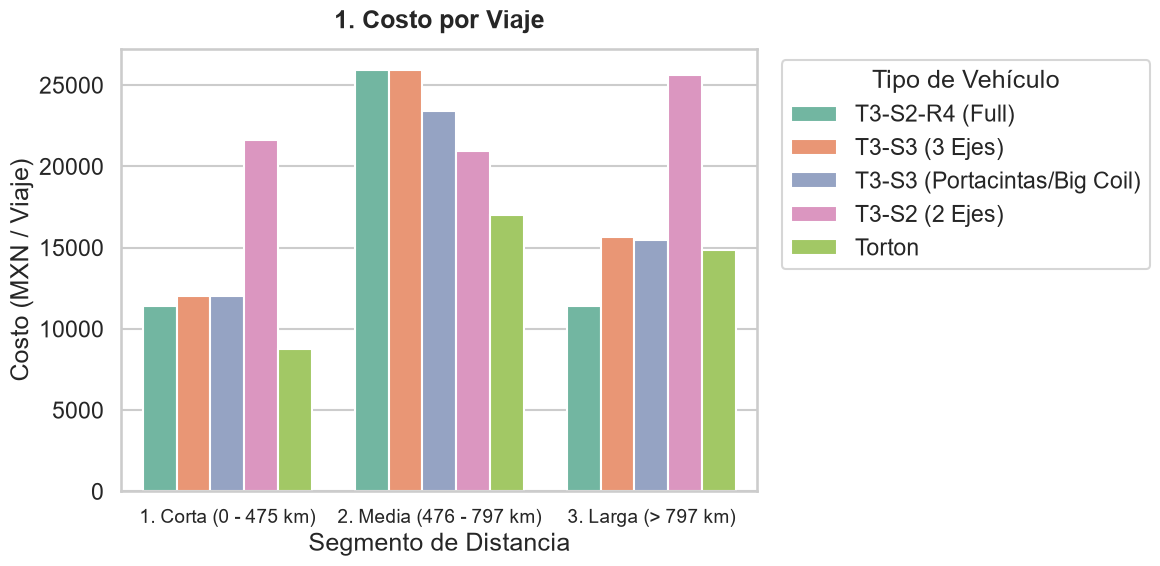

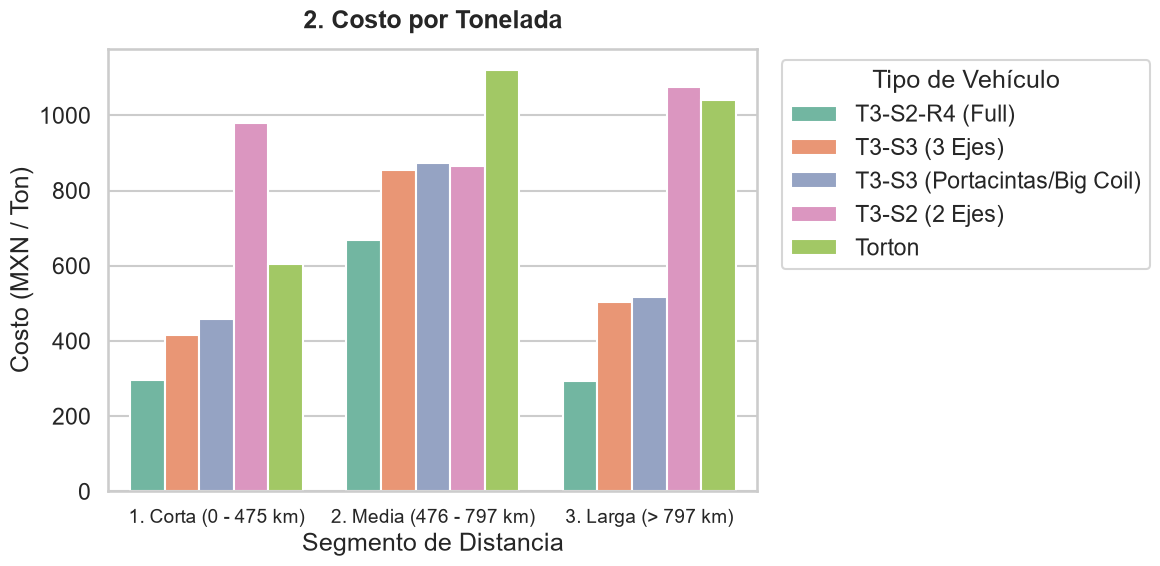

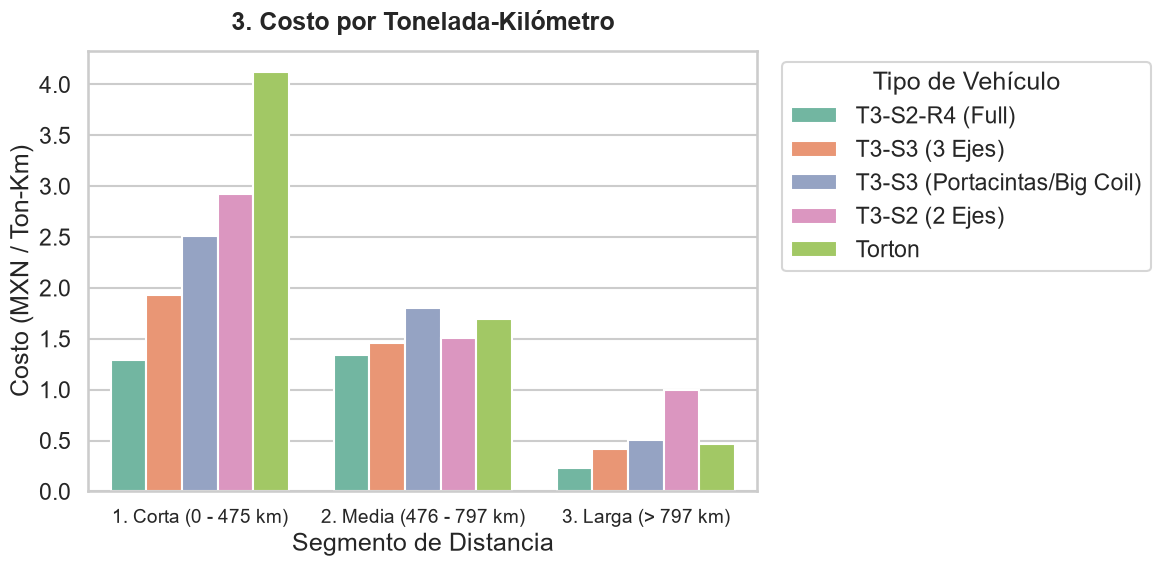

Medianas de costo para rutas LARGAS:
 | Nomenclatura_Final           |   Costo_Viaje |   Costo_Ton_Real |   Costo_Ton_Km |
|:-----------------------------|--------------:|-----------------:|---------------:|
| T3-S2 (2 Ejes)               |         25644 |          1074.66 |           1    |
| T3-S2-R4 (Full)              |         11400 |           294.16 |           0.23 |
| T3-S3 (3 Ejes)               |         15653 |           504.7  |           0.42 |
| T3-S3 (Portacintas/Big Coil) |         15500 |           517.97 |           0.5  |
| Torton                       |         14881 |          1041.69 |           0.47 |


In [10]:
# Propósito: Comparar costo por viaje, por tonelada y por ton-km según tipo de camión y distancia.
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Nomenclatura_Final'] = np.where(mascara_portacintas, 'T3-S3 (Portacintas/Big Coil)', df['Nomenclatura_Inferida'])

# Crear categorías de distancia
bins = [0, 475, 797, np.inf]
labels = ['1. Corta (0 - 475 km)', '2. Media (476 - 797 km)', '3. Larga (> 797 km)']
df['Categoria_Distancia'] = pd.cut(df['Kilometros_Ruta'], bins=bins, labels=labels)

# Filtrar vehículos objetivo
vehiculos_objetivo = [
    'T3-S2-R4 (Full)', 
    'T3-S3 (3 Ejes)', 
    'T3-S3 (Portacintas/Big Coil)', 
    'T3-S2 (2 Ejes)', 
    'Torton'
]
df_costos = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()
df_costos['Costo_Viaje'] = df_costos['Monto total']

# Configuración visual base
sns.set_theme(style="whitegrid", context="talk")
paleta = sns.color_palette('Set2', n_colors=len(vehiculos_objetivo))

# ==========================================
# GRÁFICO 1: COSTO POR VIAJE
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Viaje', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo, errorbar=None
)
plt.title('1. Costo por Viaje', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Viaje)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 2: COSTO POR TONELADA
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Ton_Real', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo,errorbar=None
)
plt.title('2. Costo por Tonelada', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Ton)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 3: COSTO POR TON-KM
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_costos, x='Categoria_Distancia', y='Costo_Ton_Km', hue='Nomenclatura_Final', 
    estimator=np.median, palette=paleta, hue_order=vehiculos_objetivo,errorbar=None
)
plt.title('3. Costo por Tonelada-Kilómetro', fontweight='bold', pad=15)
plt.ylabel('Costo (MXN / Ton-Km)')
plt.xlabel('Segmento de Distancia')
plt.legend(title='Tipo de Vehículo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(fontsize=14)
plt.tight_layout()
plt.show()

resumen_larga = df_costos[df_costos['Categoria_Distancia'] == '3. Larga (> 797 km)'].groupby('Nomenclatura_Final')[['Costo_Viaje', 'Costo_Ton_Real', 'Costo_Ton_Km']].median().round(2)
print("Medianas de costo para rutas LARGAS:\n", resumen_larga.to_markdown())

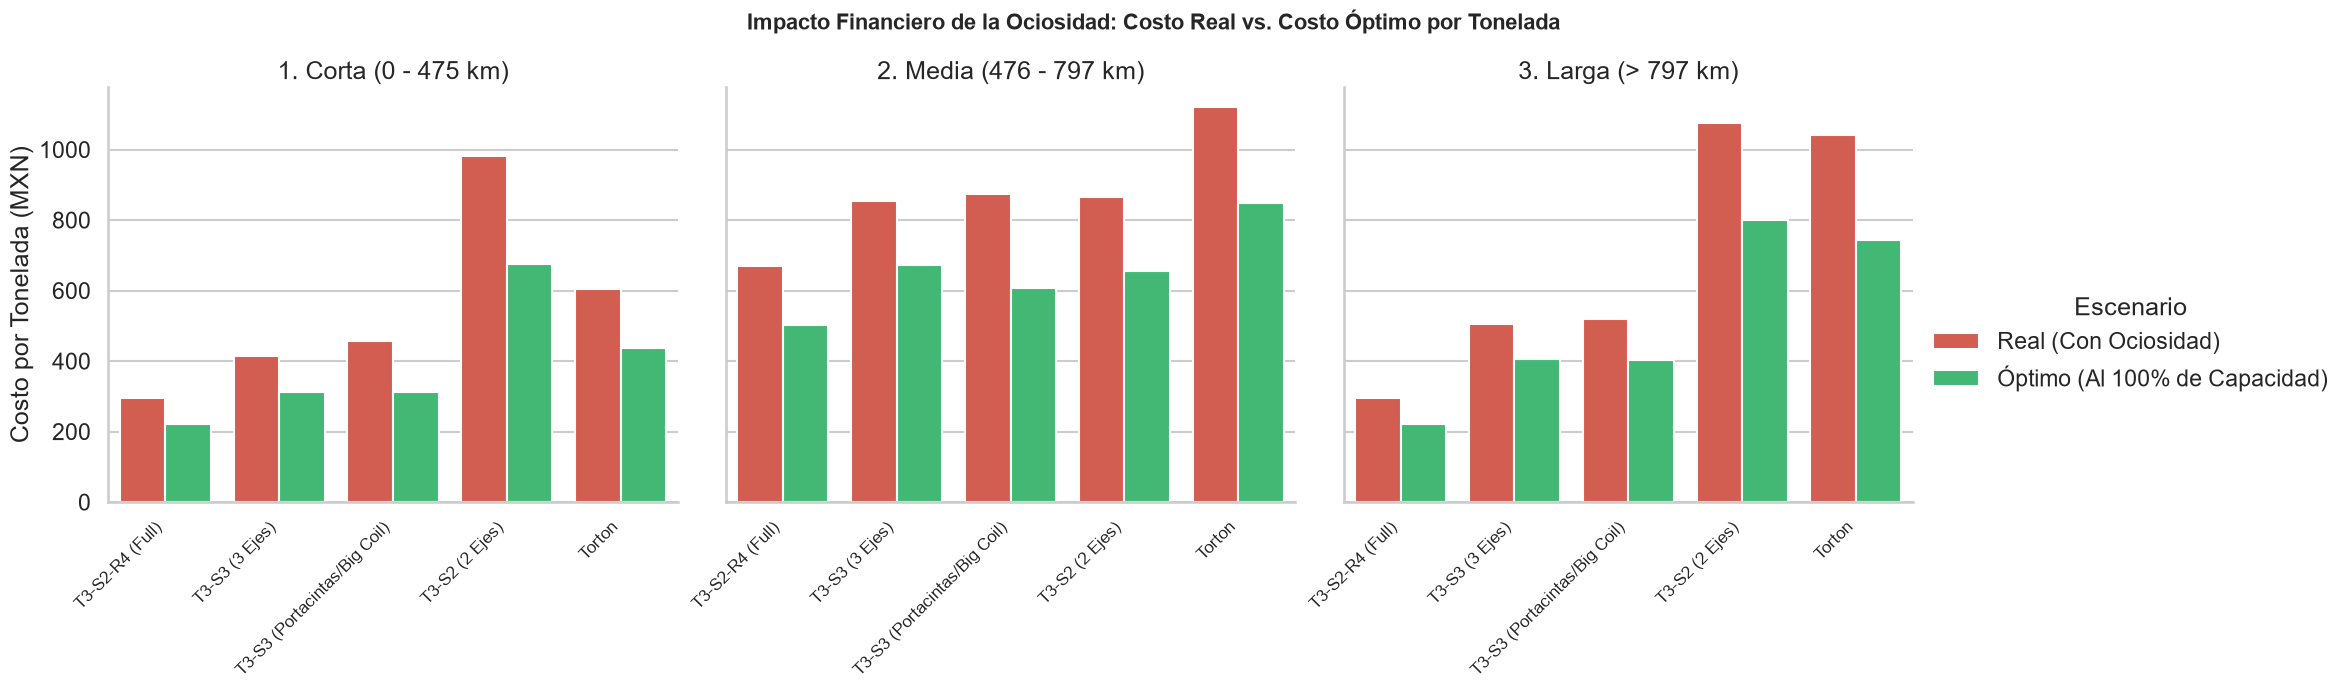

--- AHORRO POTENCIAL EVITABLE POR TIPO DE UNIDAD ---


,Nomenclatura_Final,Sobrecosto (Millones MXN)
2,T3-S3 (3 Ejes),148.88
0,T3-S2 (2 Ejes),53.62
3,T3-S3 (Portacintas/Big Coil),27.87
4,Torton,5.23
1,T3-S2-R4 (Full),2.43


'\nEjemplo con un viaje real de la capa oro (fila 10 de viajes_foraneos_oro.csv): una Plataforma de 3 ejes neumática que recorrió 135.5 km.\n\nDatos del viaje\n\nDato\tValor\nMonto total (lo que se pagó)\t$9,673 MXN\nPeso Total (carga real)\t28,724 kg → 28.724 t\nCapacidad_Max_kg (límite legal 3 ejes)\t38,500 kg → 38.5 t\nUtilización\t28.724 / 38.5 = 74.6%\nCapacidad ociosa\t38.5 − 28.724 = 9.776 t sin usar\n1. Costo por tonelada\n\nReal (con ociosidad): $9,673 / 28.724 t = $336.76 por tonelada\nÓptimo (al 100%): $9,673 / 38.5 t = $251.25 por tonelada\nSobrecosto por tonelada: 336.76 − 251.25 = $85.51 por tonelada\nEl flete costó lo mismo ($9,673) en los dos escenarios. Lo único que cambia es entre cuántas toneladas se reparte ese pago.\n\n2. Sobrecosto del viaje (lo que suma la tabla de "ahorro evitable")\n\n\nSobrecosto_Por_Viaje = Sobrecosto_Ton × Toneladas_Reales\n                     = 85.51 × 28.724 ≈ $2,456 MXN\nUna forma equivalente de verlo: si el camión hubiera ido al 100%, l

In [11]:
# Propósito: Costo real vs. óptimo (camión al 100%) por tonelada y sobrecosto total por tipo de camión (cota superior de ahorro).
bins = [0, 475, 797, np.inf]
vehiculos_objetivo = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (Portacintas/Big Coil)', 'T3-S2 (2 Ejes)', 'Torton']
df_obj = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()

# 2. Transformación para la visualización (Melt)
df_melt = df_obj.melt(id_vars=['Nomenclatura_Final', 'Categoria_Distancia'], 
                      value_vars=['Costo_Ton_Real', 'Costo_Ton_Optimo'],
                      var_name='Escenario', value_name='Costo_Ton')

df_melt['Escenario'] = df_melt['Escenario'].replace({
    'Costo_Ton_Real': 'Real (Con Ociosidad)', 
    'Costo_Ton_Optimo': 'Óptimo (Al 100% de Capacidad)'
})

# 3. Visualización comparativa
sns.set_theme(style="whitegrid", context="talk")
g = sns.catplot(
    data=df_melt, kind="bar",
    x="Nomenclatura_Final", y="Costo_Ton", hue="Escenario", col="Categoria_Distancia",
    estimator=np.median, errorbar=None, palette=['#e74c3c', '#2ecc71'], 
    height=6, aspect=1.1, sharey=True, order=vehiculos_objetivo
)

g.set_axis_labels("", "Costo por Tonelada (MXN)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45, ha='right', fontsize=12)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Impacto Financiero de la Ociosidad: Costo Real vs. Costo Óptimo por Tonelada', fontweight='bold', fontsize=16)

plt.show()

# 4. Cálculo del Ahorro Evitable Total
df_obj['Sobrecosto_Por_Viaje'] = df_obj['Sobrecosto_Ton'] * df_obj['Toneladas_Reales']
resumen_ahorro = df_obj.groupby('Nomenclatura_Final')['Sobrecosto_Por_Viaje'].sum().reset_index()
resumen_ahorro['Sobrecosto (Millones MXN)'] = (resumen_ahorro['Sobrecosto_Por_Viaje'] / 1e6).round(2)
resumen_ahorro = resumen_ahorro.sort_values('Sobrecosto (Millones MXN)', ascending=False)

print("--- AHORRO POTENCIAL EVITABLE POR TIPO DE UNIDAD ---")
display(resumen_ahorro[['Nomenclatura_Final', 'Sobrecosto (Millones MXN)']])
#Este caso se enfoca específicamente al medir el costo total por tonelada, de forma que se obtenga el siguiente ejemplo:
"""
Ejemplo con un viaje real de la capa oro (fila 10 de viajes_foraneos_oro.csv): una Plataforma de 3 ejes neumática que recorrió 135.5 km.

Datos del viaje

Dato	Valor
Monto total (lo que se pagó)	$9,673 MXN
Peso Total (carga real)	28,724 kg → 28.724 t
Capacidad_Max_kg (límite legal 3 ejes)	38,500 kg → 38.5 t
Utilización	28.724 / 38.5 = 74.6%
Capacidad ociosa	38.5 − 28.724 = 9.776 t sin usar
1. Costo por tonelada

Real (con ociosidad): $9,673 / 28.724 t = $336.76 por tonelada
Óptimo (al 100%): $9,673 / 38.5 t = $251.25 por tonelada
Sobrecosto por tonelada: 336.76 − 251.25 = $85.51 por tonelada
El flete costó lo mismo ($9,673) en los dos escenarios. Lo único que cambia es entre cuántas toneladas se reparte ese pago.

2. Sobrecosto del viaje (lo que suma la tabla de "ahorro evitable")


Sobrecosto_Por_Viaje = Sobrecosto_Ton × Toneladas_Reales
                     = 85.51 × 28.724 ≈ $2,456 MXN
Una forma equivalente de verlo: si el camión hubiera ido al 100%, las 28.724 t habrían costado 28.724 × 251.25 ≈ $7,217. Se pagaron $9,673, así que la diferencia es ≈ $2,456. Ese es el dinero que corresponde a las 9.776 t de espacio vacío (9.776 × 251.25 ≈ $2,456).

3. Costo por tonelada-kilómetro

Real: $9,673 / (28.724 t × 135.53 km) = 9,673 / 3,892.9 = $2.48 por t·km
Óptimo: $9,673 / (38.5 t × 135.53 km) = 9,673 / 5,217.8 = $1.85 por t·km
La celda del componente 1 suma ese sobrecosto de ~$2,456 por viaje en todos los viajes y lo agrupa por tipo de camión.
"""

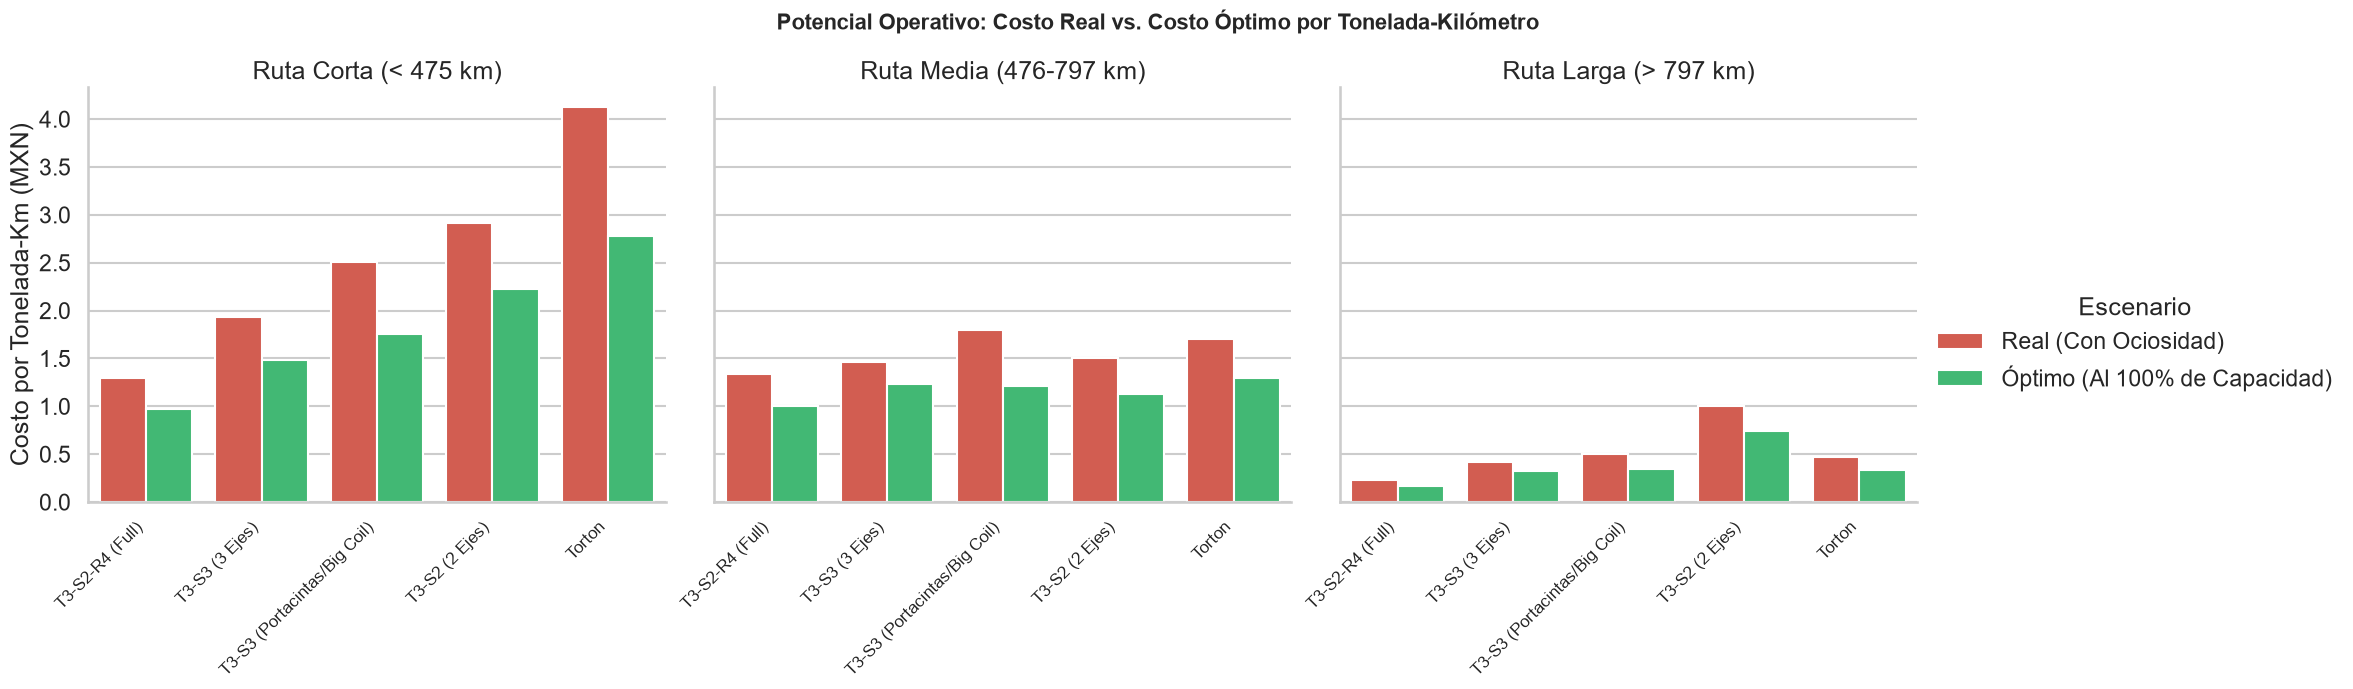

In [12]:
# Propósito: Costo real vs. óptimo por tonelada-kilómetro, por tipo de camión y distancia.
bins = [0, 475, 797, np.inf]
labels = ['Ruta Corta (< 475 km)', 'Ruta Media (476-797 km)', 'Ruta Larga (> 797 km)']
df['Categoria_Distancia'] = pd.cut(df['Kilometros_Ruta'], bins=bins, labels=labels)

vehiculos_objetivo = ['T3-S2-R4 (Full)', 'T3-S3 (3 Ejes)', 'T3-S3 (Portacintas/Big Coil)', 'T3-S2 (2 Ejes)', 'Torton']
df_obj = df[df['Nomenclatura_Final'].isin(vehiculos_objetivo)].copy()

# 2. Calcular el Costo por Ton-Km Óptimo
# (Ton-Km ideal asumiendo que siempre viajan al 100% de la capacidad legal)
df_obj['Tonelada_Kilometro_Optimo'] = df_obj['Toneladas_Maximas'] * df_obj['Kilometros_Ruta']
df_obj['Costo_Ton_Km_Optimo'] = df_obj['Monto total'] / df_obj['Tonelada_Kilometro_Optimo'].replace(0, np.nan)

# 3. Preparar el DataFrame para la visualización de comparación
df_melt_km = df_obj.melt(id_vars=['Nomenclatura_Final', 'Categoria_Distancia'], 
                         value_vars=['Costo_Ton_Km', 'Costo_Ton_Km_Optimo'],
                         var_name='Escenario', value_name='Costo')

df_melt_km['Escenario'] = df_melt_km['Escenario'].replace({
    'Costo_Ton_Km': 'Real (Con Ociosidad)', 
    'Costo_Ton_Km_Optimo': 'Óptimo (Al 100% de Capacidad)'
})

# 4. Generar el Gráfico de Barras Agrupadas
sns.set_theme(style="whitegrid", context="talk")
g = sns.catplot(
    data=df_melt_km, kind="bar",
    x="Nomenclatura_Final", y="Costo", hue="Escenario", col="Categoria_Distancia",
    estimator=np.median, errorbar=None, palette=['#e74c3c', '#2ecc71'], 
    height=6, aspect=1.1, sharey=True, order=vehiculos_objetivo
)

g.set_axis_labels("", "Costo por Tonelada-Km (MXN)")
g.set_titles("{col_name}")
g.set_xticklabels(rotation=45, ha='right', fontsize=12)

g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Potencial Operativo: Costo Real vs. Costo Óptimo por Tonelada-Kilómetro', fontweight='bold', fontsize=16)

plt.show()

In [13]:
# Propósito: Motor de right-sizing: camión más chico donde cabe la carga (filtro físico) y solo si es más barato (filtro financiero).
candidatos_right_sizing = [
    ('Tortoneta', 12000),
    ('Torton', 20000),
    ('T3-S2 (2 Ejes)', 32000),
    ('T3-S3 (3 Ejes)', 38500),
    ('T3-S2-R4 (Full)', 51500)
]

HOLGURA_SEGURIDAD = 0.95

# 3. Fase 1: Viabilidad Física
def aplicar_right_sizing_fisico(row):
    if row['Dimension_Amarra'] != 'Peso Legal' or row['Nomenclatura_Final'] == 'T3-S3 (Portacintas/Big Coil)':
        return row['Nomenclatura_Final']
    
    peso_real = row['Peso Total']
    for vehiculo, capacidad_maxima in candidatos_right_sizing:
        if peso_real <= (capacidad_maxima * HOLGURA_SEGURIDAD):
            return vehiculo
    return row['Nomenclatura_Final']

df['Vehiculo_Fisico'] = df.apply(aplicar_right_sizing_fisico, axis=1)

# 4. Fase 2: Viabilidad Financiera por Distancia
# Generamos un diccionario de referencia con las tarifas medianas por distancia
costos_medios = df.groupby(['Nomenclatura_Final', 'Categoria_Distancia'], observed=False)['Monto total'].median().to_dict()

def aplicar_filtro_financiero(row):
    veh_original = row['Nomenclatura_Final']
    veh_sugerido = row['Vehiculo_Fisico']
    distancia = row['Categoria_Distancia']
    
    if veh_original == veh_sugerido:
        return veh_original
        
    costo_real_pagado = row['Monto total']
    
    # Estimamos cuánto nos cobraría el nuevo vehículo en esa ruta
    clave_esperada = (veh_sugerido, distancia)
    costo_esperado = costos_medios.get(clave_esperada, np.inf)
    
    # Solo cambiamos si el vehículo sugerido es efectivamente más barato
    if costo_esperado >= costo_real_pagado:
        return veh_original
        
    return veh_sugerido

print("Ejecutando motor de optimización financiera...")
df['Vehiculo_Recomendado_Final'] = df.apply(aplicar_filtro_financiero, axis=1)

# 5. Resultados
cambiados_financieros = df[df['Nomenclatura_Final'] != df['Vehiculo_Recomendado_Final']]
print(f"\nViajes consolidados con viabilidad financiera garantizada: {len(cambiados_financieros):,} viajes.")

transicion = pd.crosstab(
    df['Nomenclatura_Final'], 
    df['Vehiculo_Recomendado_Final'], 
    rownames=['Original'], 
    colnames=['Sugerido']
)
print("\nMatriz Logística (Optimizada por Costo/Distancia):")
display(transicion)

Ejecutando motor de optimización financiera...

Viajes consolidados con viabilidad financiera garantizada: 4,090 viajes.

Matriz Logística (Optimizada por Costo/Distancia):


Sugerido,Cama Baja Doble Piso,Heavy,Plataforma larga 48 pies,T3-S2 (2 Ejes),T3-S2-R4 (Full),T3-S3 (3 Ejes),T3-S3 (Portacintas/Big Coil),Torton,Tortoneta
Original,,,,,,,,,
Cama Baja Doble Piso,167,0,0,0,0,0,0,0,0
Heavy,0,34,0,0,0,0,0,0,0
Plataforma larga 48 pies,0,0,34,307,0,0,0,2,0
Plataforma larga 53 pies,0,0,0,2,0,0,0,0,0
T3-S2 (2 Ejes),0,0,0,8783,0,5,0,35,0
T3-S2-R4 (Full),0,0,0,0,814,0,0,0,0
T3-S3 (3 Ejes),0,0,0,2692,964,33895,0,69,1
T3-S3 (Portacintas/Big Coil),0,0,0,0,0,0,5660,0,0
Torton,0,0,0,0,0,0,0,1661,13


Calculando el ahorro neto ejecutable fila por fila...
Iniciando Bootstrap con 1000 simulaciones (remuestreando 1318 rutas)...


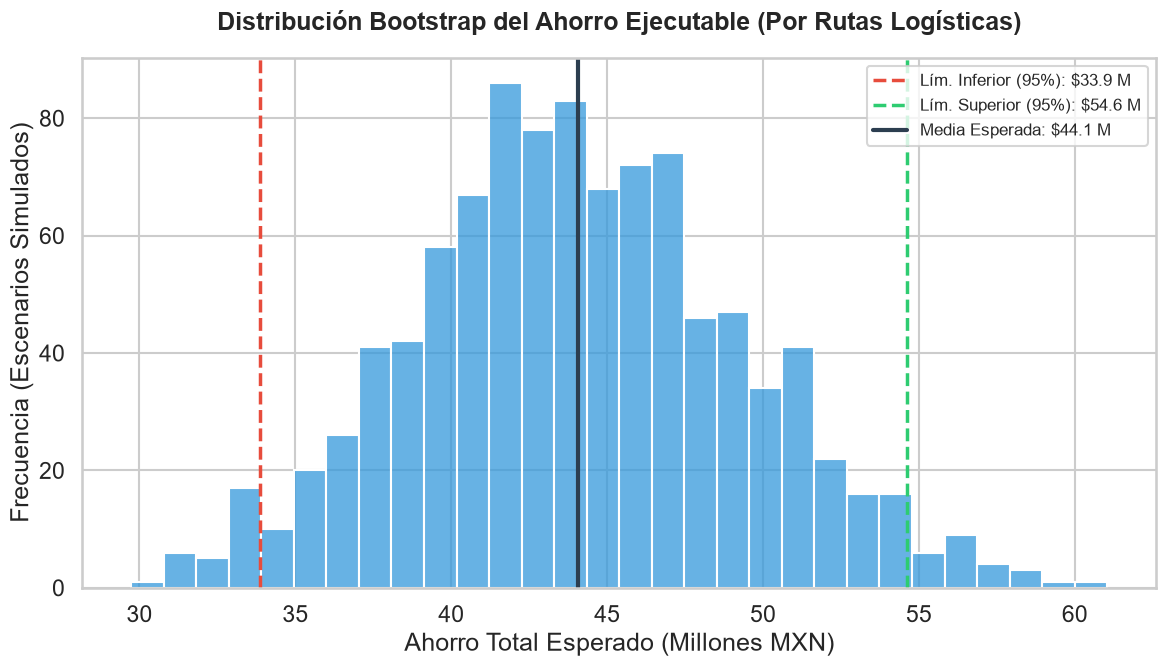

--- RESULTADOS DEL BOOTSTRAP POR CONGLOMERADOS ---
Con un 95% de confianza estadística, el modelo de Right-Sizing generará un ahorro neto anual entre:
>> $33.86 y $54.61 Millones de MXN.
>> Promedio central esperado: $44.08 Millones de MXN.


In [14]:
# Propósito: Ahorro ejecutable por viaje e intervalo de confianza con bootstrap por conglomerados (rutas).
# Definir la función para calcular el ahorro neto por viaje
costos_medios = df.groupby(['Nomenclatura_Final', 'Categoria_Distancia'], observed=False)['Monto total'].median().to_dict()

def calcular_ahorro_viaje(row):
    original = row['Nomenclatura_Final']
    sugerido = row['Vehiculo_Recomendado_Final']
    
    if original == sugerido:
        return 0.0
        
    costo_real = row['Monto total']
    costo_esperado = costos_medios.get((sugerido, row['Categoria_Distancia']), np.inf)
    
    if costo_esperado < costo_real:
        return costo_real - costo_esperado
    return 0.0

print("Calculando el ahorro neto ejecutable fila por fila...")
df['Ahorro_Ejecutable'] = df.apply(calcular_ahorro_viaje, axis=1)

# 2. Configurar el Motor de Cluster Bootstrap (Conglomerados por Ruta Logística)
df['Ruta_ID'] = df['PLANTA_ORIGEN'] + " - " + df['Ciudad Destino']
ahorro_por_ruta = df.groupby('Ruta_ID')['Ahorro_Ejecutable'].sum()

B = 1000 # Número de simulaciones
ahorros_totales = []
rutas_unicas = df['Ruta_ID'].unique()
n_clusters = len(rutas_unicas)

print(f"Iniciando Bootstrap con {B} simulaciones (remuestreando {n_clusters} rutas)...")
np.random.seed(42) # Semilla para reproducibilidad académica

for _ in range(B):
    # Muestreo con reemplazo de las rutas
    rutas_muestra = np.random.choice(rutas_unicas, size=n_clusters, replace=True)
    rutas_counts = pd.Series(rutas_muestra).value_counts()
    
    # Sumar el ahorro del escenario simulado
    suma_iteracion = sum(ahorro_por_ruta.get(ruta, 0) * conteo for ruta, conteo in rutas_counts.items())
    ahorros_totales.append(suma_iteracion)

# 3. Calcular Métricas Estadísticas de Riesgo
ahorros_millones = np.array(ahorros_totales) / 1e6
limite_inf = np.percentile(ahorros_millones, 2.5)
limite_sup = np.percentile(ahorros_millones, 97.5)
media_boot = np.mean(ahorros_millones)

# 4. Generar la Visualización Final
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid", context="talk")
sns.histplot(ahorros_millones, bins=30, color='#3498db', edgecolor='white')

# Líneas de confianza
plt.axvline(limite_inf, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Lím. Inferior (95%): ${limite_inf:.1f} M')
plt.axvline(limite_sup, color='#2ecc71', linestyle='--', linewidth=2.5, label=f'Lím. Superior (95%): ${limite_sup:.1f} M')
plt.axvline(media_boot, color='#2c3e50', linestyle='-', linewidth=3, label=f'Media Esperada: ${media_boot:.1f} M')

plt.title('Distribución Bootstrap del Ahorro Ejecutable (Por Rutas Logísticas)', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Ahorro Total Esperado (Millones MXN)')
plt.ylabel('Frecuencia (Escenarios Simulados)')
plt.legend(frameon=True, fontsize=12)

plt.tight_layout()
plt.show()

print("--- RESULTADOS DEL BOOTSTRAP POR CONGLOMERADOS ---")
print(f"Con un 95% de confianza estadística, el modelo de Right-Sizing generará un ahorro neto anual entre:")
print(f">> ${limite_inf:.2f} y ${limite_sup:.2f} Millones de MXN.")
print(f">> Promedio central esperado: ${media_boot:.2f} Millones de MXN.")